# Week 4 · Part D — The e-commerce review figure
**Data Visualization (CDB601220)**

One 2×2 figure, produced by a notebook that runs top-to-bottom the same way every time:

| Panel | What it shows |
|---|---|
| 1 | Daily sessions: raw in light grey, **7-day centred rolling mean** on top |
| 2 | Day-of-week × hour-of-day heatmap of mean sessions (sequential colormap) |
| 3 | Treemap of category → sub-category **net** revenue (one hue per parent category) |
| 4 | The same eight sub-categories as sorted horizontal bars, values printed |

Output: `outputs/partD_figure.png` at **300 dpi**.

> **How to run:** keep this notebook in `week4/assignments/` (with `w4_clean.py`, `tslib.py`, `vizlib.py`, `data/`), then *Kernel → Restart & Run All*.
> Install once: `pip install pandas numpy matplotlib seaborn scipy statsmodels squarify`

The cleaning logic is written as one function per fault in `w4_clean.py`; this notebook calls them **one at a time** and prints what each did.

In [2]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

HERE = Path.cwd()                      # run the notebook from week4/assignments
DATA = HERE / "data"
OUT  = HERE / "outputs"; OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(HERE))

import tslib as T                      # Week 4 toolkit (imports Week 3's vizlib)
from tslib import PALETTE, style_defaults, save_fig
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"]
SOFT = PALETTE["ink_soft"]
SRC = "Source: CDB601220 Week 4 synthetic course data (Superior University Lahore)."

import w4_clean as W
import squarify, matplotlib.ticker
from matplotlib.patches import Rectangle
PD_ = OUT          # Part D writes straight into outputs/
raw = pd.read_csv(DATA / "sessions_hourly.csv")

---
## 1 · Find the faults before plotting anything
The four calls from the brief, in order.

In [3]:
raw.info()
display(raw.describe().T)
display(raw.device.value_counts())
print(raw.ts.head(10).tolist())

<class 'pandas.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ts           12670 non-null  str  
 1   sessions     12670 non-null  int64
 2   orders       12670 non-null  int64
 3   revenue_pkr  12670 non-null  int64
 4   device       12670 non-null  str  
dtypes: int64(3), str(2)
memory usage: 797.6 KB


,count,mean,std,min,25%,50%,75%,max
sessions,12670.0,947.951381,646.882994,-1.0,435.0,756.0,1368.00,9811.0
orders,12670.0,30.016732,20.089492,4.0,14.0,24.0,42.00,304.0
revenue_pkr,12670.0,132564.968824,100150.706234,10350.0,58036.5,102359.0,182232.25,1652881.0


device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
desktop     318
MOBILE      246
Name: count, dtype: int64

['2024-04-29 11:00:00', '2024-10-26 05:00:00', '2025-08-04 20:00:00', '2024-10-05 19:00:00', '2025-01-22 20:00:00', '05/10/2024 09:00', '2024-08-11 15:00:00', '12/04/2025 10:00', '2024-07-24 02:00:00', '2025-03-27 11:00:00']


**Visible in that output alone (4 of 6):**
1. `ts` is text in **two formats** — `2024-04-29 11:00:00` and `05/10/2024 09:00`.
2. The rows are **not in time order** (the first ten timestamps jump around).
3. `device` has **six spellings** (`Mobile`, `mobile`, `MOBILE`, `Desktop`, `desktop`, `Tablet`) for three devices.
4. `sessions` has a minimum of **−1** — a sentinel, not a count (a count cannot be negative).

**Visible only once the index is a real `DatetimeIndex` (the other 2):**
5. **Duplicated hours.**
6. **Whole days never recorded** — plus the extract stops part-way through a month.

---
## 2 · Fault 1 — two timestamp formats (the parse trap)
`pd.to_datetime(df.ts)` guesses one format and turns the other into `NaT`. `format="mixed"` parses everything and **silently moves rows to the wrong day**. The slash rows are **day-first**: their first field reaches 31 and their second never exceeds 12, so a month-first reading is impossible for those rows.

In [4]:
ts_parsed, log_parse = W.parse_timestamps(raw)
print({k: v for k, v in log_parse.items() if k != "rule"})
print("rule:", log_parse["rule"])

dmg = W.mixed_parse_damage(raw, ts_parsed)
print("\nwhat format='mixed' would have done:")
print(f"  mixed  range: {dmg['mixed_min']}  ->  {dmg['mixed_max']}   ({dmg['span_days_mixed']} days)")
print(f"  correct range: {dmg['correct_min']}  ->  {dmg['correct_max']}   ({dmg['span_days_correct']} days)")
print(f"  rows moved to a wrong date: {dmg['rows_on_wrong_date']:,}   (row count identical, nothing raised)")

assert ts_parsed.notna().all()
assert ts_parsed.min() == pd.Timestamp("2024-04-01 00:00") and ts_parsed.max() == pd.Timestamp("2025-09-11 23:00")
print("\nOK: range 2024-04-01 .. 2025-09-11, as expected")

{'fault': 'mixed timestamp formats', 'n_iso': 9019, 'n_slash': 3651, 'slash_first_field_max': 31, 'slash_second_field_max': 12, 'rows_removed': 0}
rule: parse ISO rows as %Y-%m-%d %H:%M:%S and slash rows as %d/%m/%Y %H:%M (first field reaches 31, second never exceeds 12 => day-first)

what format='mixed' would have done:
  mixed  range: 2024-01-04 01:00:00  ->  2025-12-08 22:00:00   (704 days)
  correct range: 2024-04-01 00:00:00  ->  2025-09-11 23:00:00   (528 days)
  rows moved to a wrong date: 1,382   (row count identical, nothing raised)

OK: range 2024-04-01 .. 2025-09-11, as expected


---
## 3 · Faults 2–6, one at a time

In [5]:
df = raw.drop(columns="ts").set_index(pd.DatetimeIndex(ts_parsed, name="ts"))
logs = [log_parse]

# --- Fault 2: order
df, l = W.sort_by_time(df); logs.append(l); print("2) sort:", l)

# --- Fault 3: device labels
df, l = W.normalise_device(df); logs.append(l); print("\n3) device:", l["before"], "->", l["after"])

# --- Audit the index: the six slide-10 checks, BEFORE removing duplicates
a_before = T.audit_index(df, "h")
print("\naudit_index (hourly, before de-duplication):")
print({k: v for k, v in a_before.items() if k != "missing_dates"})

2) sort: {'fault': 'rows not in time order', 'rule': 'sort_index()', 'already_sorted': False, 'rows_removed': 0}

3) device: {'Mobile': 6994, 'Desktop': 3452, 'mobile': 883, 'Tablet': 777, 'desktop': 318, 'MOBILE ': 246} -> {'Mobile': 8123, 'Desktop': 3770, 'Tablet': 777}

audit_index (hourly, before de-duplication):
{'dtype_ok': True, 'monotonic': True, 'n_rows': 12670, 'n_duplicated': 286, 'n_missing': 312, 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00'), 'partial_tail': False, 'tail_period': '2025-09-11', 'tail_count': 24}


In [6]:
# --- Fault 5: duplicated hours (prove they are copies first)
df, l = W.drop_duplicate_hours(df); logs.append(l)
print("5) duplicates:", {k: v for k, v in l.items() if k != "rule"}); print("   rule:", l["rule"])

# --- Fault 4: sentinel -1
df, l = W.sentinel_to_nan(df); logs.append(l)
print("\n4) sentinel:", {k: v for k, v in l.items() if k != "rule"}); print("   rule:", l["rule"])
df, l = W.impute_sentinel_hours(df); logs.append(l)
print("   fill:", {k: v for k, v in l.items() if k != "rule"}); print("   rule:", l["rule"])

# --- Fault 6: gaps - counted on the HOURLY index, BEFORE resampling
a_after = T.audit_index(df, "h")
print("\naudit_index (hourly, after cleaning):", {k: v for k, v in a_after.items() if k != "missing_dates"})
print("first missing hours:", a_before["missing_dates"][:3], "...")
daily, hourly_full, l = W.to_daily(df); logs.append(l)
print("\n6) gaps:", {k: v for k, v in l.items() if k not in ("rule", "gap_days")})
print("   gap days:", l["gap_days"])
print("   rule:", l["rule"])
tail = W.partial_tail(daily); logs.append(tail)
print("   partial tail:", {k: v for k, v in tail.items() if k != "rule"})

# --- sanity: every recorded day has exactly 24 hours (no daylight-saving in Pakistan)
hpd = df.groupby(df.index.normalize()).size()
print("\nhours per recorded day:", hpd.value_counts().to_dict(), " (all 24 -> no collector oddities left)")
assert (hpd == 24).all()
assert len(daily) == 529 and daily.sessions.isna().sum() == 13

5) duplicates: {'fault': 'duplicated hours', 'n_timestamps_duplicated': 286, 'all_pairs_identical': True, 'rows_removed': 286}
   rule: keep first row per timestamp (verified: every duplicate pair is value-identical)

4) sentinel: {'fault': 'sentinel -1 in sessions', 'n_sentinel': 287, 'other_columns_touched': False, 'rows_removed': 0}
   rule: sessions == -1 -> NaN (flagged in sessions_missing)
   fill: {'fault': 'sentinel hours (fill)', 'n_filled': 287, 'sessions_filled_total': 280239.0}
   rule: median of same day-of-week x hour; flagged in sessions_imputed

audit_index (hourly, after cleaning): {'dtype_ok': True, 'monotonic': True, 'n_rows': 12384, 'n_duplicated': 0, 'n_missing': 312, 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00'), 'partial_tail': False, 'tail_period': '2025-09-11', 'tail_count': 24}
first missing hours: ['2024-05-18 00:00:00', '2024-05-18 01:00:00', '2024-05-18 02:00:00'] ...

6) gaps: {'fault': 'days never recorded', 'n_missing_hours': 312, 'n_gap_days': 

In [7]:
# the cleaning log - the table Part E quotes
clog = pd.DataFrame([
    ["1 mixed timestamp formats", f"{logs[0]['n_iso']:,} ISO + {logs[0]['n_slash']:,} dd/mm/yyyy parsed with their own formats", 0, f"format='mixed' would move {dmg['rows_on_wrong_date']:,} rows to wrong dates (span 704 days instead of 528)"],
    ["2 rows not in time order", "sort_index()", 0, "unsorted -> sorted"],
    ["3 device labels", "strip + title-case", 0, "6 spellings -> 3 devices"],
    ["5 duplicated hours", "keep first; all pairs verified value-identical", logs[3]["rows_removed"], f"12,670 -> {12670 - logs[3]['rows_removed']:,} rows"],
    ["4 sentinel sessions == -1", "-> NaN, then same day-of-week x hour median, flagged", 0, f"{logs[4]['n_sentinel']} hours ({logs[4]['n_sentinel']/len(df)*100:.1f}% of rows) refilled"],
    ["6 days never recorded", "left as NaN (line breaks); never zero-filled", 0, f"{logs[6]['n_gap_days']} days / {logs[6]['n_missing_hours']} hours"],
    ["6b partial final month", "shaded and labelled on the chart; never compared as a monthly total", 0, f"{tail['tail_month']}: {tail['days_present']} of {tail['days_in_month']} days"],
], columns=["fault", "rule", "rows removed", "count / effect"])
display(clog)

,fault,rule,rows removed,count / effect
0,1 mixed timestamp formats,"9,019 ISO + 3,651 dd/mm/yyyy parsed with their...",0,"format='mixed' would move 1,382 rows to wrong ..."
1,2 rows not in time order,sort_index(),0,unsorted -> sorted
2,3 device labels,strip + title-case,0,6 spellings -> 3 devices
3,5 duplicated hours,keep first; all pairs verified value-identical,286,"12,670 -> 12,384 rows"
4,4 sentinel sessions == -1,"-> NaN, then same day-of-week x hour median, f...",0,287 hours (2.3% of rows) refilled
5,6 days never recorded,left as NaN (line breaks); never zero-filled,0,13 days / 312 hours
6,6b partial final month,shaded and labelled on the chart; never compar...,0,2025-09: 11 of 30 days


---
## 4 · The catalogue: make it a tree, then roll it up
A hierarchy chart needs a **tree** — every child has exactly one parent, and children sum to the parent. Two faults: a SKU with **two parents**, and **negative** net revenue (negatives have no area).

In [8]:
cat_clean, sub, cat_logs = W.clean_catalogue(DATA / "revenue_catalogue.csv")
for l in cat_logs: print({k: v for k, v in l.items() if k != "rule"}); print("   rule:", l["rule"]); print()

s8 = pd.read_csv(DATA / "shares_eight.csv").set_index("subcategory").share_pct
diff = (sub.set_index("subcategory").share_pct - s8).abs()
print("max |share - shares_eight.csv| =", round(float(diff.max()), 3), "percentage points   (brief: within 0.3 is correct; ~0.9 means a fault was missed)")
assert diff.max() < 0.3
display(sub.round(2))

{'fault': 'SKU with two parents (not a tree)', 'skus': ['SKU-0127'], 'rows_removed': 1, 'removed_parent': ['Wearables'], 'kept_parent': ['Audio'], 'net_revenue_removed_pkr_m': 14.8275}
   rule: keep the row whose sku_name prefix matches its sub-category's home; drop the other copy

{'fault': 'negative net revenue', 'n_negative_skus': 7, 'sum_negative_pkr_m': -1.0693000000000001, 'rows_removed': 0, 'by_subcategory': {'Accessories': {'count': 1, 'sum': -0.0001}, 'Drones': {'count': 2, 'sum': -0.1136}, 'Footwear': {'count': 2, 'sum': -0.6249}, 'Wearables': {'count': 2, 'sum': -0.3307}}}
   rule: never drawn as area; netted inside sub-category totals (all totals > 0) and reported

{'fault': 'levels rolled up', 'n_skus_in': 344, 'n_subcategories': 8, 'other_bucket': {'n_categories': 0, 'value_pkr_m': 0.0}, 'total_net_pkr_m': 1711.3815, 'rows_removed': 0}
   rule: 344 SKUs summed to 8 sub-categories; depth cut at sub-category; no 'Other' bucket needed (smallest sub-category is 2.4% of the to

,category,subcategory,net_revenue_pkr_m,n_skus,share_pct
0,Audio & Imaging,Audio,256.54,44,14.99
1,Audio & Imaging,Cameras,102.16,48,5.97
2,Audio & Imaging,Drones,41.18,37,2.41
3,Computing,Laptops,311.99,38,18.23
4,Lifestyle,Footwear,187.52,39,10.96
5,Lifestyle,Wearables,159.96,53,9.35
6,Mobile,Accessories,228.24,45,13.34
7,Mobile,Phones,423.77,40,24.76


---
## 5 · The figure

In [9]:
CAT_HUE = {"Mobile": BLUE, "Computing": ORANGE, "Audio & Imaging": GREEN, "Lifestyle": PINK}   # one hue per parent
def text_on(hexcol):
    r, g, b = matplotlib.colors.to_rgb(hexcol); lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
    return "white" if lum < 0.45 else INK
def tint(hexcol, k):                      # k = 0 -> full hue, k -> toward white
    r, g, b = matplotlib.colors.to_rgb(hexcol); return (r + (1 - r) * k, g + (1 - g) * k, b + (1 - b) * k)

# ---------------- numbers used in the titles (computed, not typed)
s_daily = daily.sessions
roll7 = s_daily.rolling(7, center=True, min_periods=5).mean()        # window: 7 days, centred; >=5 of 7 days present
monthly_median = s_daily.groupby(s_daily.index.to_period("M")).median()
full_months = monthly_median.iloc[:-1]                                # drop the partial Sep 2025
first_year = full_months.iloc[:12]                                    # Apr 2024 - Mar 2025
peak1_m = first_year.idxmax(); peak1 = first_year.max()
after = full_months[full_months.index > peak1_m]
trough_m = after.idxmin(); trough = after.min()
latest_m = full_months.index[-1]; latest = full_months.iloc[-1]
ratio = peak1 / full_months.iloc[0]
peak_month = peak1_m.strftime("%b %Y")
assert latest > peak1, "the later rise no longer passes the first peak - re-word the Panel 1 title"

hr = df.loc[~df.sessions_imputed.astype(bool)] if "sessions_imputed" in df else df
heat = hr.groupby([hr.index.dayofweek, hr.index.hour]).sessions.mean().unstack()
heat.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
pk_day, pk_hr = np.unravel_index(np.nanargmax(heat.to_numpy()), heat.shape)
pk_val = heat.iat[pk_day, pk_hr]
wk_same = heat.iloc[:5, pk_hr].mean()
print(f"monthly median sessions/day: Apr-24 {full_months.iloc[0]:,.0f} -> {peak_month} {peak1:,.0f} ({ratio:.2f}x) -> {trough_m.strftime('%b %Y')} {trough:,.0f} -> {latest_m.strftime('%b %Y')} {latest:,.0f}")
print(f"heatmap peak: {heat.index[pk_day]} {pk_hr:02d}:00 = {pk_val:,.0f}/hour vs weekday mean at that hour {wk_same:,.0f}  ({pk_val / wk_same:.1f}x)")

total = sub.net_revenue_pkr_m.sum()
top2 = sub.nlargest(2, "net_revenue_pkr_m")
top2_share = top2.share_pct.sum()
small = sub.nsmallest(1, "net_revenue_pkr_m").iloc[0]
print(f"top two: {', '.join(top2.subcategory)} = {top2_share:.1f}% | smallest: {small.subcategory} {small.share_pct:.1f}%")

monthly median sessions/day: Apr-24 14,440 -> Dec 2024 25,220 (1.75x) -> May 2025 21,097 -> Aug 2025 26,403
heatmap peak: Sat 20:00 = 2,336/hour vs weekday mean at that hour 1,731  (1.3x)
top two: Phones, Laptops = 43.0% | smallest: Drones 2.4%


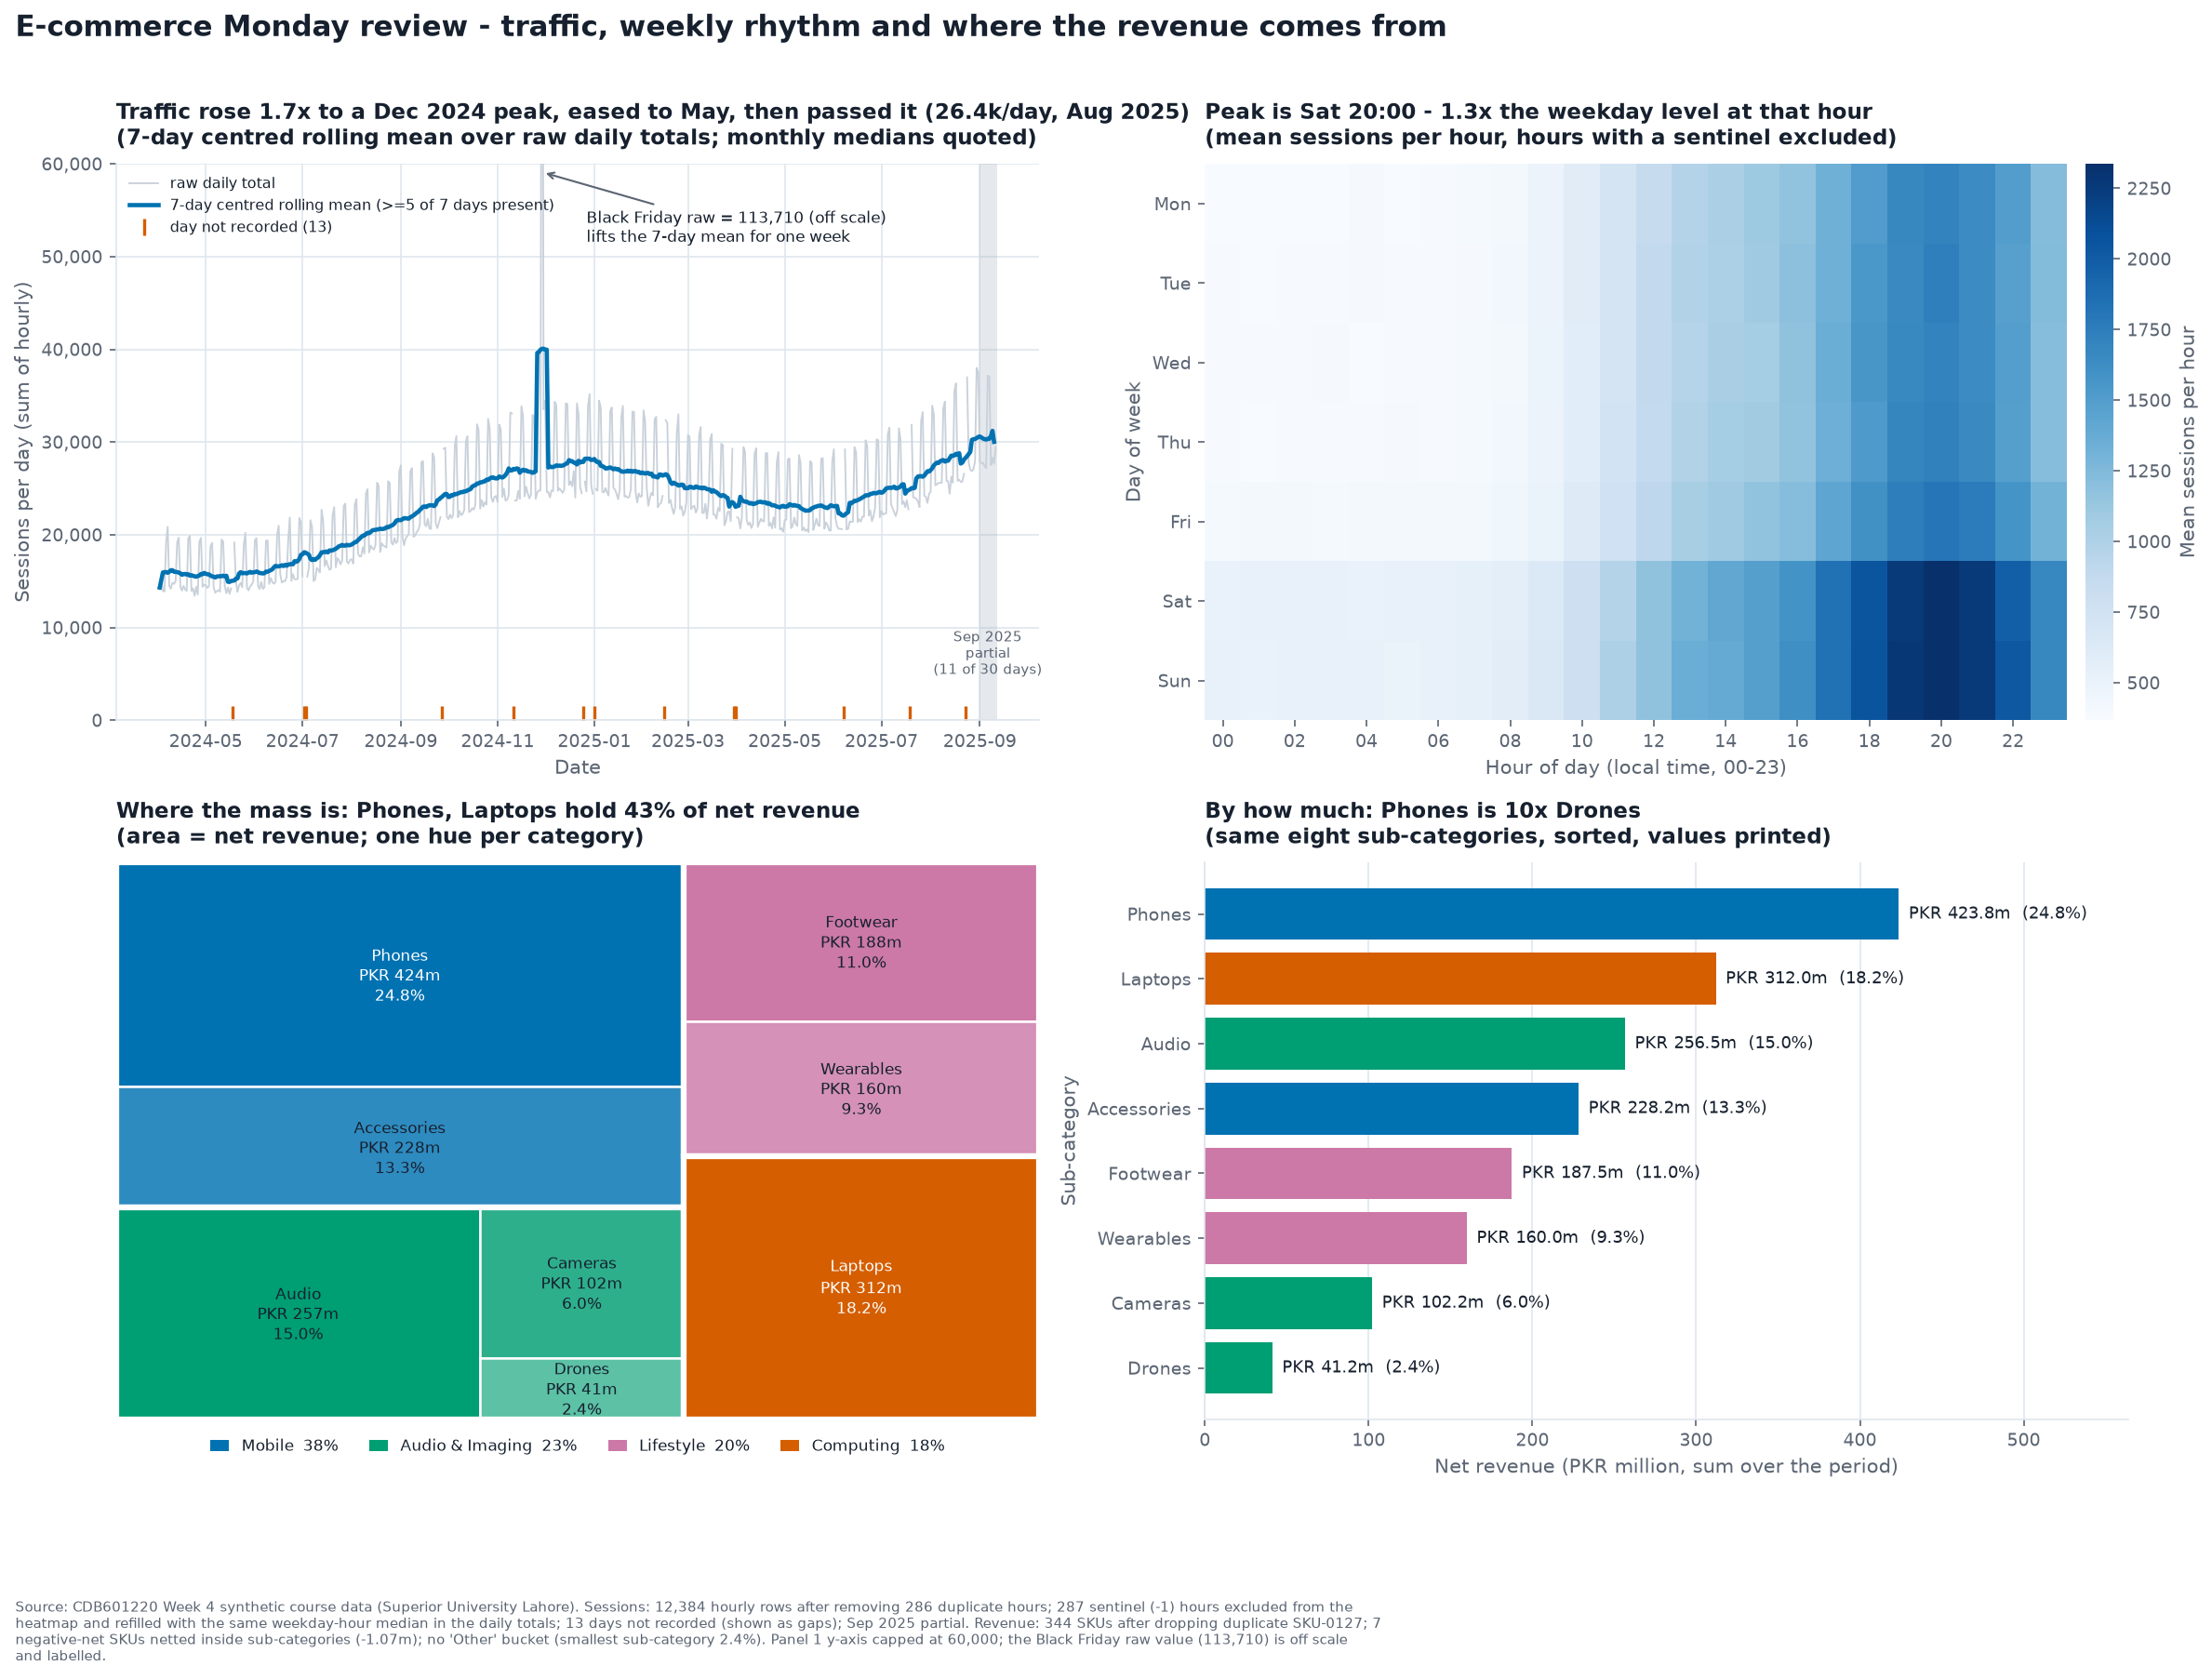

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11.2))
ax1, ax2, ax3, ax4 = axes.ravel()

# ===== PANEL 1 - daily series, raw grey, 7-day centred mean on top
ax1.plot(s_daily.index, s_daily, color="#C9D1DA", linewidth=0.9, label="raw daily total")
ax1.plot(roll7.index, roll7, color=BLUE, linewidth=2.2, label="7-day centred rolling mean (>=5 of 7 days present)")
tail_start = pd.Timestamp(tail["tail_start"])
ax1.axvspan(tail_start, s_daily.index.max() + pd.Timedelta(days=1), color=GREY, alpha=0.25, lw=0)
ax1.text(tail_start + pd.Timedelta(days=5), 5000, "Sep 2025\npartial\n(11 of 30 days)", fontsize=7, ha="center", color=SOFT)
gap_idx = pd.to_datetime(logs[6]["gap_days"])
ax1.plot(gap_idx, np.full(len(gap_idx), 600), "|", color=ORANGE, markersize=9, markeredgewidth=1.6, label="day not recorded (13)")
bf = pd.Timestamp("2024-11-29")
YCAP = 60000          # y-axis capped so the weekly rhythm and trend stay readable; the one off-scale day is labelled
ax1.set_ylim(0, YCAP)
ax1.annotate(f"Black Friday raw = {s_daily[bf]:,.0f} (off scale)\nlifts the 7-day mean for one week", xy=(bf, YCAP * 0.985),
             xytext=(bf + pd.Timedelta(days=28), YCAP * 0.86), fontsize=8, color=INK, arrowprops=dict(arrowstyle="->", color=SOFT))
ax1.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax1.set_title(f"Traffic rose {ratio:.1f}x to a {peak_month} peak, eased to {trough_m.strftime('%b')}, then passed it ({latest/1000:.1f}k/day, {latest_m.strftime('%b %Y')})\n(7-day centred rolling mean over raw daily totals; monthly medians quoted)", fontsize=11)
ax1.set_xlabel("Date"); ax1.set_ylabel("Sessions per day (sum of hourly)")
ax1.legend(loc="upper left", fontsize=7.5)

# ===== PANEL 2 - heatmap
im = ax2.imshow(heat.to_numpy(), cmap=PALETTE["sequential"], aspect="auto", origin="upper")
ax2.set_xticks(range(0, 24, 2)); ax2.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
ax2.set_yticks(range(7)); ax2.set_yticklabels(heat.index)
ax2.grid(False); ax2.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax2.set_xlabel("Hour of day (local time, 00-23)"); ax2.set_ylabel("Day of week")
ax2.set_title(f"Peak is {heat.index[pk_day]} {pk_hr:02d}:00 - {pk_val / wk_same:.1f}x the weekday level at that hour\n(mean sessions per hour, hours with a sentinel excluded)", fontsize=11)
cb = fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.02); cb.set_label("Mean sessions per hour")
cb.outline.set_visible(False)

# ===== PANEL 3 - nested treemap, one hue per parent category
catsum = sub.groupby("category").net_revenue_pkr_m.sum().sort_values(ascending=False)
norm = squarify.normalize_sizes(catsum.to_numpy(), 100, 100)
cat_rects = squarify.squarify(norm, 0, 0, 100, 100)
for (cname, cval), cr in zip(catsum.items(), cat_rects):
    kids = sub[sub.category == cname].sort_values("net_revenue_pkr_m", ascending=False)
    kn = squarify.normalize_sizes(kids.net_revenue_pkr_m.to_numpy(), cr["dx"], cr["dy"])
    kr = squarify.squarify(kn, cr["x"], cr["y"], cr["dx"], cr["dy"])
    for i, ((_, k), r) in enumerate(zip(kids.iterrows(), kr)):
        colour = tint(CAT_HUE[cname], 0.0 if i == 0 else min(0.18 * i, 0.5))
        ax3.add_patch(Rectangle((r["x"], r["y"]), r["dx"], r["dy"], facecolor=colour, edgecolor="white", linewidth=1.2))
        if r["dx"] > 9 and r["dy"] > 9:
            ax3.text(r["x"] + r["dx"] / 2, r["y"] + r["dy"] / 2,
                     f"{k.subcategory}\nPKR {k.net_revenue_pkr_m:,.0f}m\n{k.share_pct:.1f}%",
                     ha="center", va="center", fontsize=8, color=text_on(matplotlib.colors.to_hex(colour)), linespacing=1.3)
    ax3.add_patch(Rectangle((cr["x"], cr["y"]), cr["dx"], cr["dy"], fill=False, edgecolor="white", linewidth=3))
ax3.set_xlim(0, 100); ax3.set_ylim(0, 100); ax3.invert_yaxis(); ax3.axis("off")
handles = [Rectangle((0, 0), 1, 1, facecolor=CAT_HUE[c]) for c in catsum.index]
ax3.legend(handles, [f"{c}  {v / total * 100:.0f}%" for c, v in catsum.items()], loc="upper center",
           bbox_to_anchor=(0.5, -0.01), ncol=4, fontsize=8, frameon=False, handlelength=1.2)
ax3.set_title(f"Where the mass is: {', '.join(top2.subcategory)} hold {top2_share:.0f}% of net revenue\n(area = net revenue; one hue per category)", fontsize=11)

# ===== PANEL 4 - sorted horizontal bars, values printed
bars = sub.sort_values("net_revenue_pkr_m")
bh = ax4.barh(bars.subcategory, bars.net_revenue_pkr_m, color=[CAT_HUE[c] for c in bars.category])
for b, (_, r) in zip(bh, bars.iterrows()):
    ax4.text(r.net_revenue_pkr_m + 6, b.get_y() + b.get_height() / 2, f"PKR {r.net_revenue_pkr_m:,.1f}m  ({r.share_pct:.1f}%)", va="center", fontsize=8.5)
ax4.set_xlim(0, bars.net_revenue_pkr_m.max() * 1.33)
ax4.set_xlabel("Net revenue (PKR million, sum over the period)"); ax4.set_ylabel("Sub-category")
ax4.set_title(f"By how much: {top2.subcategory.iloc[0]} is {top2.net_revenue_pkr_m.iloc[0] / small.net_revenue_pkr_m:.0f}x {small.subcategory}\n(same eight sub-categories, sorted, values printed)", fontsize=11)
ax4.grid(axis="y", visible=False)

fig.suptitle("E-commerce Monday review - traffic, weekly rhythm and where the revenue comes from", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.97))

note = (f"Source: CDB601220 Week 4 synthetic course data (Superior University Lahore). Sessions: {len(df):,} hourly rows after removing {logs[3]['rows_removed']} duplicate hours; "
        f"{logs[4]['n_sentinel']} sentinel (-1) hours excluded from the heatmap and refilled with the same weekday-hour median in the daily totals; "
        f"{logs[6]['n_gap_days']} days not recorded (shown as gaps); Sep 2025 partial. "
        f"Revenue: {len(cat_clean)} SKUs after dropping duplicate SKU-0127; {cat_logs[1]['n_negative_skus']} negative-net SKUs netted inside sub-categories "
        f"({cat_logs[1]['sum_negative_pkr_m']:.2f}m); no 'Other' bucket (smallest sub-category {small.share_pct:.1f}%).")
import textwrap
note = textwrap.fill(note + f" Panel 1 y-axis capped at {YCAP:,}; the Black Friday raw value ({s_daily[bf]:,.0f}) is off scale and labelled.", width=190)
save_fig(fig, PD_ / "partD_figure.png", note=note)       # savefig BEFORE show
plt.show()

In [11]:
from PIL import Image
im = Image.open(OUT / "partD_figure.png")
print("saved outputs/partD_figure.png:", im.size, "px  dpi =", im.info.get("dpi"))
assert round(im.info["dpi"][0]) >= 299, "export is below 300 dpi"

saved outputs/partD_figure.png: (4757, 3610) px  dpi = (299.9994, 299.9994)


In [12]:
# persist for Part E and for re-use
daily.to_csv(OUT / "sessions_daily_clean.csv")
res_D = {"cleaning_logs": logs, "catalogue_logs": cat_logs,
         "figure_numbers": {"ratio": float(ratio), "peak_month": peak_month, "trough_month": trough_m.strftime("%b %Y"), "peak1": float(peak1), "trough": float(trough), "latest_month": str(latest_m), "latest": float(latest), "first_median": float(full_months.iloc[0]), "heatmap_peak": [str(heat.index[pk_day]), int(pk_hr), float(pk_val), float(wk_same)],
                            "top2": top2.subcategory.tolist(), "top2_share": float(top2_share), "smallest": [small.subcategory, float(small.share_pct)]},
         "shares": sub.set_index("subcategory").share_pct.round(3).to_dict(), "mixed_parse_damage": dmg}
(OUT / "partD_results.json").write_text(json.dumps(res_D, indent=2, default=str))
print("saved sessions_daily_clean.csv and partD_results.json")

saved sessions_daily_clean.csv and partD_results.json


---
## 6 · What each panel answers (one sentence each — expanded in Part E)
1. **Panel 1 — "Where is traffic really heading?"** A line over time, the 7-day centred mean cancelling the weekly rhythm so the trajectory shows; raw stays in grey underneath.
2. **Panel 2 — "When in the week do people actually visit?"** Two categorical axes and one magnitude: a heatmap, with a single-hue sequential colormap because there is no midpoint.
3. **Panel 3 — "Where is the mass?"** Containment shows hierarchy; area shows size; the values are printed because area is read to only about ±20%.
4. **Panel 4 — "By how much?"** Position on a common scale — the best channel — for the same eight numbers, sorted so rank reads off the page.